# Final predictive figures

Final predictive visuals for the portfolio README.

This notebook uses only the **closed/frozen experiment results**. It does not retrain models or alter the methodology.

The README will use only two predictive figures:

1. V2 ROC-AUC by feature year.
2. Main V2 model comparison.

The V1 → V2 comparison and the sensitivity excluding feature year 2020 are kept as tables/text because they do not need separate charts.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("../images")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. V2 out-of-time performance by feature year

This is the main predictive figure.

It shows the external ROC-AUC in each feature year for:

- persistence baseline;
- Financial Ridge;
- Financial + Sporting Ridge.

The horizontal reference at 0.50 indicates random discrimination.


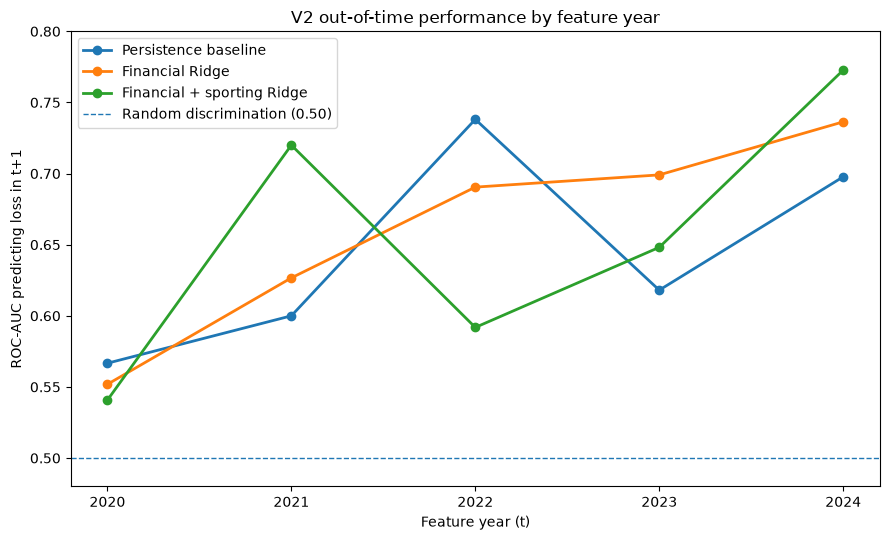

In [ ]:
v2_yearly = pd.DataFrame({
    'feature_year': [2020, 2021, 2022, 2023, 2024],
    'Persistence baseline': [0.566667, 0.600000, 0.738095, 0.618056, 0.697727],
    'Financial Ridge': [0.551852, 0.626667, 0.690476, 0.699074, 0.736364],
    'Financial + sporting Ridge': [0.540741, 0.720000, 0.591837, 0.648148, 0.772727],
})

fig, ax = plt.subplots(figsize=(9, 5.5))

for column in [
    'Persistence baseline',
    'Financial Ridge',
    'Financial + sporting Ridge',
]:
    ax.plot(
        v2_yearly['feature_year'],
        v2_yearly[column],
        marker='o',
        linewidth=2,
        label=column,
    )

ax.axhline(
    0.50,
    linestyle='--',
    linewidth=1,
    label='Random discrimination (0.50)',
)

ax.set_xlabel('Feature year (t)')
ax.set_ylabel('ROC-AUC predicting loss in t+1')
ax.set_title('V2 out-of-time performance by feature year')
ax.set_xticks(v2_yearly['feature_year'])
ax.set_ylim(0.48, 0.80)
ax.legend()

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / '01_v2_auc_by_year.png',
    dpi=180,
    bbox_inches='tight',
)

plt.show()

## 2. Main V2 model comparison

This figure summarizes the principal **absolute mean external-fold ROC-AUC** for the closed V2 specifications.

The fitted models are shown as points, while the vertical dashed line marks the persistence baseline (0.644). The x-axis starts at 0.50 so the visual does not exaggerate the relatively small differences between models.

This is the final comparison used in the README. The `without_2020` analysis remains a separate sensitivity table rather than a second model-comparison chart.


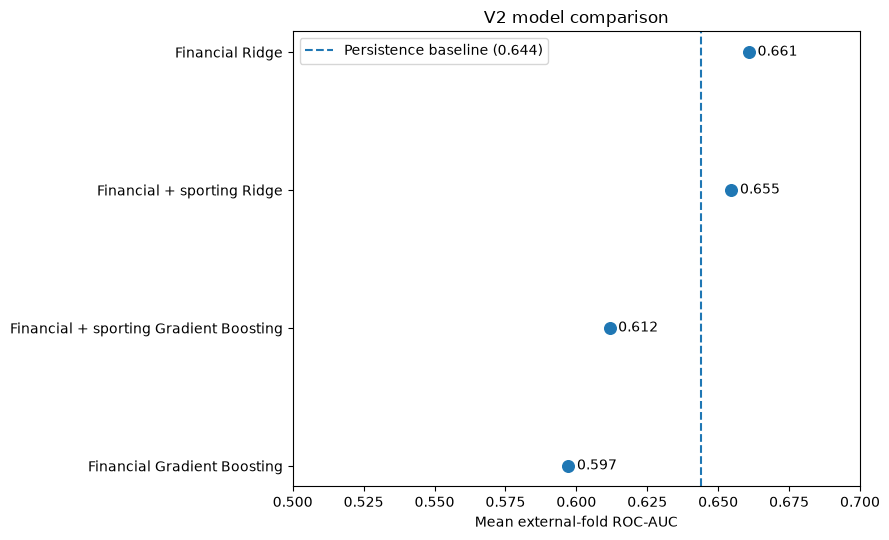

In [ ]:
v2_models = pd.DataFrame({
    'model': [
        'Financial Ridge',
        'Financial + sporting Ridge',
        'Financial Gradient Boosting',
        'Financial + sporting Gradient Boosting',
    ],
    'mean_external_fold_auc': [
        0.660886,
        0.654691,
        0.597225,
        0.611745,
    ],
})

v2_models = v2_models.sort_values(
    'mean_external_fold_auc'
).reset_index(drop=True)

baseline_auc = 0.644109

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.scatter(
    v2_models['mean_external_fold_auc'],
    v2_models['model'],
    s=70,
)

ax.axvline(
    baseline_auc,
    linestyle='--',
    linewidth=1.5,
    label=f'Persistence baseline ({baseline_auc:.3f})',
)

for _, row in v2_models.iterrows():
    ax.text(
        row['mean_external_fold_auc'] + 0.003,
        row['model'],
        f"{row['mean_external_fold_auc']:.3f}",
        va='center',
    )

ax.set_xlabel('Mean external-fold ROC-AUC')
ax.set_title('V2 model comparison')
ax.set_xlim(0.50, 0.70)
ax.legend()

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / '02_v2_model_summary.png',
    dpi=180,
    bbox_inches='tight',
)

plt.show()

## Sensitivity analysis — excluding feature year 2020

The sensitivity analysis remains a table rather than a third chart.

It is a robustness check, not a replacement for the main specification.


In [ ]:
sensitivity = pd.DataFrame({
    'model': [
        'Persistence baseline',
        'Financial Ridge',
        'Financial + sporting Ridge',
        'Financial Gradient Boosting',
        'Financial + sporting Gradient Boosting',
    ],
    'main': [
        0.644109,
        0.660886,
        0.654691,
        0.597225,
        0.611745,
    ],
    'without_2020': [
        0.663470,
        0.679393,
        0.669759,
        0.642802,
        0.656839,
    ],
})

sensitivity

,model,main,without_2020
0,Persistence baseline,0.644109,0.663470
1,Financial Ridge,0.660886,0.679393
2,Financial + sporting Ridge,0.654691,0.669759
3,Financial Gradient Boosting,0.597225,0.642802
4,Financial + sporting Gradient Boosting,0.611745,0.656839


## Interpretation to preserve

- V2 Financial Ridge modestly exceeds the persistence baseline in the main analysis.
- Adding sporting variables does not produce a robust incremental improvement over the V2 financial specification.
- Gradient Boosting does not outperform Ridge.
- Performance varies materially across external years, so the mean ROC-AUC should not be interpreted without the yearly results.
- The without-2020 analysis supports the same broad interpretation and remains a sensitivity analysis.
